# Project 3 - Step 2: Core code with a clean architecture

The Step 1 notebook had everything in one place. Now the code is split into:

| Part | Folder / file | What it does |
|---|---|---|
| **Core** | `topopt3d/` | mesh, boundary conditions, FEA, filter, optimizer. No plotting, no GUI |
| Plotting | `plotting.py` | matplotlib helpers for notebooks only |
| Tests | `tests/test_core.py` | automatic checks (the Step 1 tests + regression) |
| GUI | `gui/` (Step 4) | will only call the core functions |

The core is used in 4 lines: **mesh → boundary conditions → settings → run**.
The optimizer reports progress through a **callback**, so a notebook can print it and the GUI can
redraw a 3D view or stop the run, without the core knowing who is listening.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from topopt3d import VoxelMesh, BoundaryConditions, TOSettings, run_topopt
from plotting import plot_voxels, plot_side_view, plot_history

## 1. Cantilever, written out with the core API
Same problem as Step 1 Test 4 (`topopt3d.problems.cantilever` does the same in one line).

In [4]:
# (1) mesh: 60 x 20 x 4 voxels of size 1
mesh = VoxelMesh.box(nelx=60, nely=20, nelz=4, lx=60, ly=20, lz=4)
print(mesh)

# (2) boundary conditions
bc = BoundaryConditions(mesh)
bc.fix(mesh.nodes_on_plane(axis=0, value=0.0))                               # clamp face x = 0
load_nodes = mesh.nodes_in_box((60, 10, -np.inf), (60, 10, np.inf))          # line x = 60, y = 10
bc.load(load_nodes, total_force=(0, -1, 0))
print(f"{len(bc.fixed_dofs)} fixed DOFs, load on {len(load_nodes)} nodes")

# (3) settings: penalty and filter size can be changed here (rmin in element sizes)
settings = TOSettings(volfrac=0.3, penal=3, rmin=1.5, max_iter=100)
print(settings)

VoxelMesh(grid 60 x 20 x 4, voxel [1.0, 1.0, 1.0], 4800 elements, 6405 nodes, 19215 DOFs)
315 fixed DOFs, load on 5 nodes
TOSettings(volfrac=0.3, penal=3, rmin=1.5, move=0.2, tol=0.01, max_iter=100, E=1.0, nu=0.25, x_min=0.001, solver='auto')


In [5]:
# (4) run, with a callback that prints every 10 iterations
def show_progress(info):
    if info["iter"] % 10 == 0 or info["iter"] == 1:
        print(f"It {info['iter']:3d} | c = {info['c']:9.4f} | vol = {info['vol']:.3f} | change = {info['change']:.4f}")

result = run_topopt(mesh, bc, settings, callback=show_progress)
print(f"converged = {result.converged}, {result.iterations} iterations, {result.time:.1f} s, "
      f"c = {result.compliance:.4f}")

It   1 | c = 1087.5600 | vol = 0.300 | change = 0.2000
It  10 | c =  179.0208 | vol = 0.300 | change = 0.2000
It  20 | c =   90.6576 | vol = 0.300 | change = 0.1354
It  30 | c =   82.1927 | vol = 0.300 | change = 0.0241
It  40 | c =   82.1105 | vol = 0.300 | change = 0.0119
converged = True, 48 iterations, 43.6 s, c = 82.1089


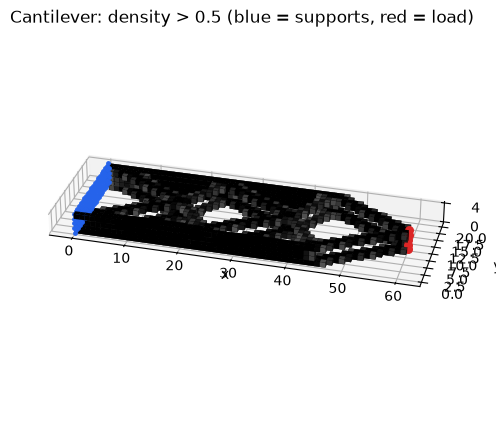

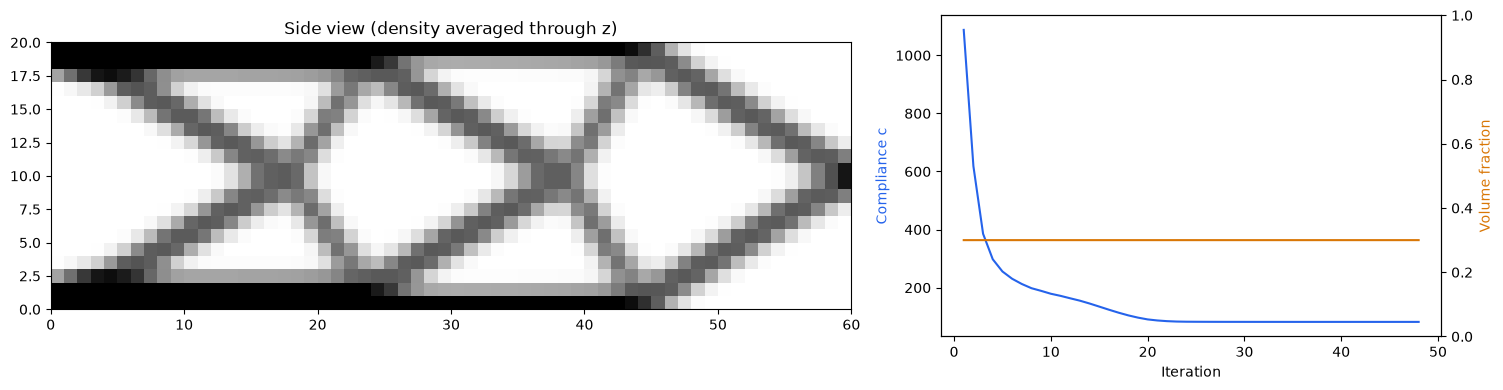

In [6]:
ax = plot_voxels(mesh, result.x, title="Cantilever: density > 0.5 (blue = supports, red = load)",
                 show_bcs=bc)
ax.view_init(elev=30, azim=-75); ax.set_zticks([0, 4])
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.6, 1]})
plot_side_view(mesh, result.x, "Side view (density averaged through z)", axes[0])
plot_history(result, axes[1])
plt.tight_layout(); plt.show()

## 2. A non-box shape: L-bracket from a voxel mask
`VoxelMesh.from_mask` accepts any True/False voxel array. This is how an STL part will enter in Step 3
(voxelize the STL → mask → mesh). Classic L-bracket: top face clamped, downward load at the tip of the arm.

VoxelMesh(grid 30 x 30 x 3, voxel [1.0, 1.0, 1.0], 1728 elements, 2548 nodes, 7644 DOFs)
converged = True, 85 iterations, 25.6 s


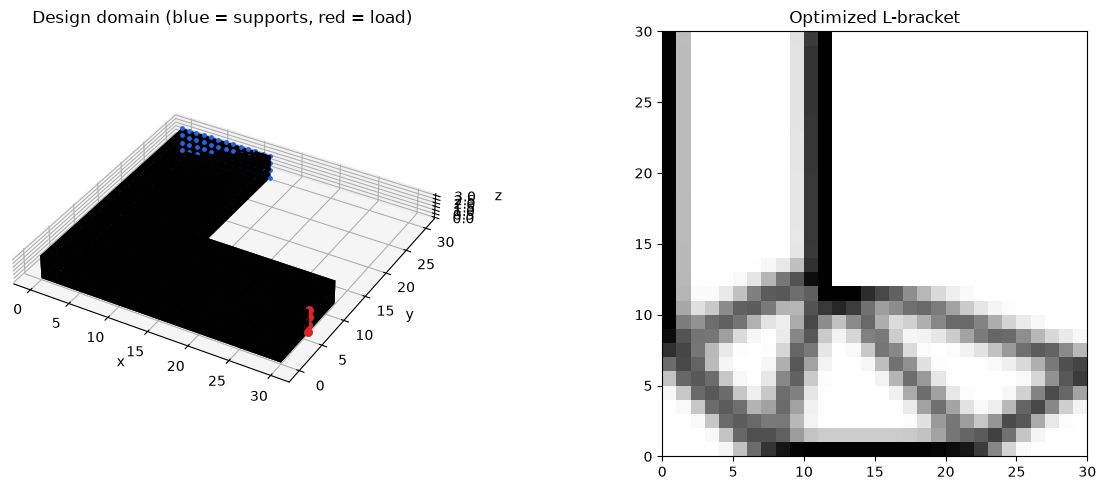

In [7]:
n, t = 30, 3                                     # 30 x 30 voxels in x-y, 3 thick
mask = np.ones((n, n, t), dtype=bool)
mask[12:, 12:, :] = False                        # cut away the upper-right block -> L shape
mesh_L = VoxelMesh.from_mask(mask, size=(1, 1, 1))
print(mesh_L)

bc_L = BoundaryConditions(mesh_L)
bc_L.fix(mesh_L.nodes_on_plane(axis=1, value=30.0))                           # top of the vertical leg
bc_L.load(mesh_L.nodes_in_box((30, 6, -np.inf), (30, 6, np.inf)), (0, -1, 0))   # tip of the arm

res_L = run_topopt(mesh_L, bc_L, TOSettings(volfrac=0.3, penal=3, rmin=1.5, max_iter=150))
print(f"converged = {res_L.converged}, {res_L.iterations} iterations, {res_L.time:.1f} s")

fig = plt.figure(figsize=(14, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
plot_voxels(mesh_L, np.ones(mesh_L.n_elem), title="Design domain (blue = supports, red = load)",
            ax=ax, show_bcs=bc_L)
ax.view_init(elev=35, azim=-60)
plot_side_view(mesh_L, res_L.x, "Optimized L-bracket", fig.add_subplot(1, 2, 2))
plt.tight_layout(); plt.show()

## 3. Automatic tests
The Step 1 tests are now in `tests/test_core.py` and run with one command (about 1.5 minutes).
Run them after every change to the core to make sure nothing broke.

In [ ]:
import sys
!"{sys.executable}" -m pytest -q -p no:cacheprovider tests